# Archived coursework — original outputs
**Not rerun:** the source workbook `invoices - updated.xlsx` was not supplied and could not be recovered from the notebook outputs. Saved outputs below come from the original coursework, not the corrected portfolio run. They cannot be independently verified without the workbook.

This notebook is retained as evidence of the original methods. Predictive results are exploratory: categorical encoders are fitted before splitting; several methods are compared on the same test set; the ANN validation subset shares preprocessing fitted to the larger training set. Feature availability and chronological ordering also require checking against the source data before claims of forecasting or leakage-free performance.


In [1]:

# first i will import necessary libraries and load the data
# getting the first 5 columns of the dataframe to know what data i am dealing with
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_excel('invoices - updated.xlsx')
df.head()

,tax_number,invoice_number,issue_date,collection_type,invoice_sub_type,invoice_category,invoice_discount_amount,invoice_tax_amount,buyer_identification,buyer_name,days_overdue,expected_payment_amount
0,120985374,T7OPZRYKM,1708014393,CREDIT,EXPORT,GENERAL_SALES,0.0,106.23,NaN,NaN,0,649.84
1,748392615,2BFOJ03E5,1749262653,CASH,LOCAL,INCOME,0.0,135.67,NaN,NaN,12,1437.72
2,382915476,MD4FU4NP1,1642622798,CASH,LOCAL,INCOME,0.0,96.66,NaN,NaN,12,1216.49
3,382915476,V4IUP8311,1706758339,CREDIT,EXPORT,SPECIAL_SALES,0.0,81.02,NaN,NaN,0,1817.24
4,382915476,VURP4E9V3,1694894569,CREDIT,AREA_OF_DEVELOPMENT,INCOME,0.0,120.53,NaN,NaN,0,1244.63


In [2]:
#dropping unnecessery columns
df = df.drop(columns = ['buyer_identification','buyer_name', 'tax_number', 'invoice_number', 'issue_date'])

In [3]:
# after dropping unnecessary columns i will check the statistical summary of the dataframe
# even though its a simple line of code, it gives me a lot of information about the data 
df.describe()
# this cell allow me to get measueres like the measures of central tendency and measures of dispersion

,invoice_discount_amount,invoice_tax_amount,days_overdue,expected_payment_amount
count,532057.000000,532057.000000,532057.000000,532057.000000
mean,109.600338,111.087331,6.792669,1620.316440
std,477.190197,275.696583,15.641736,2928.275601
min,0.000000,0.000000,0.000000,23.310000
25%,0.000000,13.850000,0.000000,634.850000
50%,0.000000,54.120000,3.000000,1178.540000
75%,58.260000,137.270000,10.000000,2019.990000
max,46689.450000,15999.990000,510.000000,109175.910000


Measures of frequency

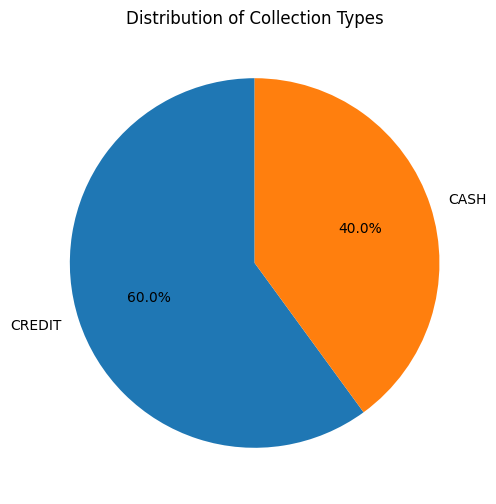

In [4]:

plt.figure(figsize=(10,6))
plt.pie(df['collection_type'].value_counts(), labels=df['collection_type'].unique(), autopct="%1.1f%%", startangle=90)
plt.title('Distribution of Collection Types')
plt.show()

# this visualization show the relative frequency of the collection types in the dataset
# we can see that credit is used more than cash, meaning that most clients tend to use credit more.

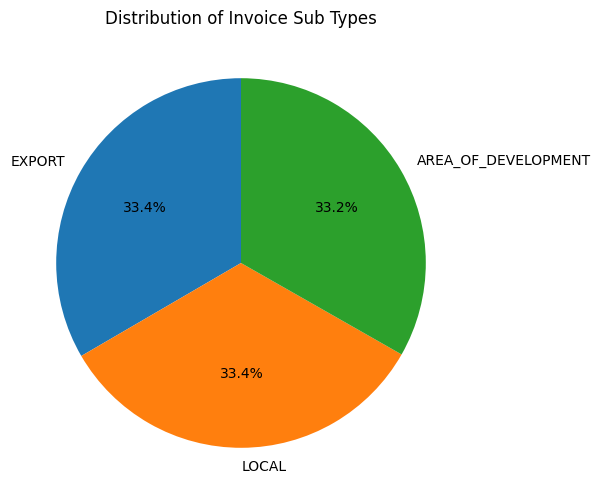

In [5]:
plt.figure(figsize=(10,6))
plt.pie(df['invoice_sub_type'].value_counts(), labels=df['invoice_sub_type'].unique(), autopct="%1.1f%%", startangle=90)
plt.title('Distribution of Invoice Sub Types')
plt.show()
# this visualization show the relative frequency of the invoice sub types in the dataset
# we can see that it is distributed almost equally between the three sub types.
# this means that we are not dealing with a dominating sub type in the dataset.

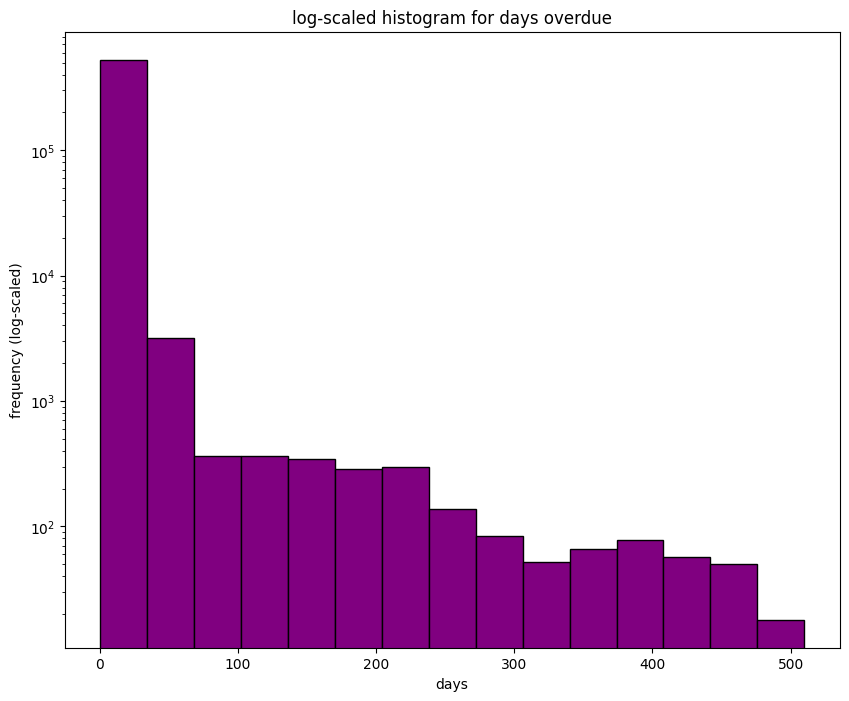

In [6]:
plt.figure(figsize = (10, 8))
plt.hist(df['days_overdue'], bins = 15, color= 'purple', edgecolor = 'black', log = True)
plt.title("log-scaled histogram for days overdue")
plt.xlabel("days")
plt.ylabel("frequency (log-scaled)")
plt.show()


the next three visulizations show that the expected payment amount, invoice tax amount and invoice tax amount are the highest with the export sub type, after that comes local and finally the area of development. which means that the event that export sub type has the highest discount mean, but it also pays the most. and the least is the area od development sub type. 

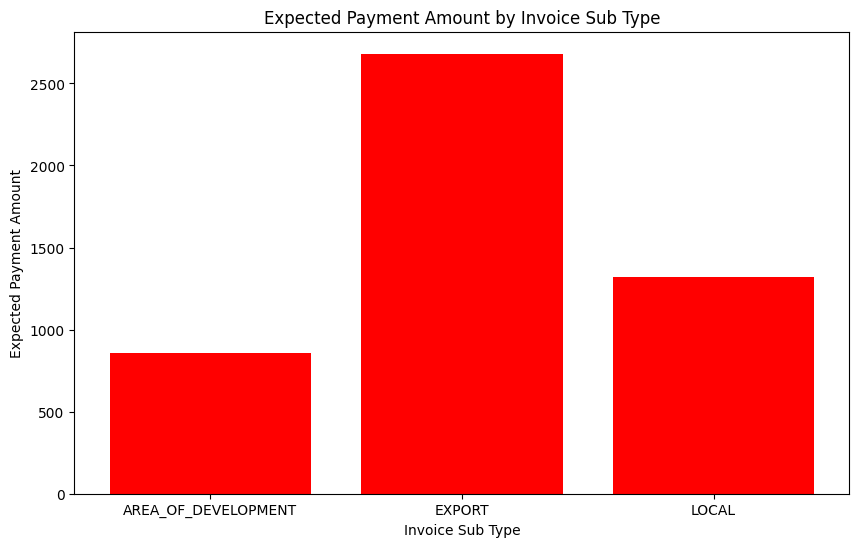

In [7]:
test2 = df.groupby('invoice_sub_type')['expected_payment_amount'].mean()
plt.figure(figsize=(10,6))
plt.bar(test2.index, test2.values, color= 'red')
plt.title("Expected Payment Amount by Invoice Sub Type")
plt.xlabel("Invoice Sub Type")
plt.ylabel("Expected Payment Amount")
plt.show() 

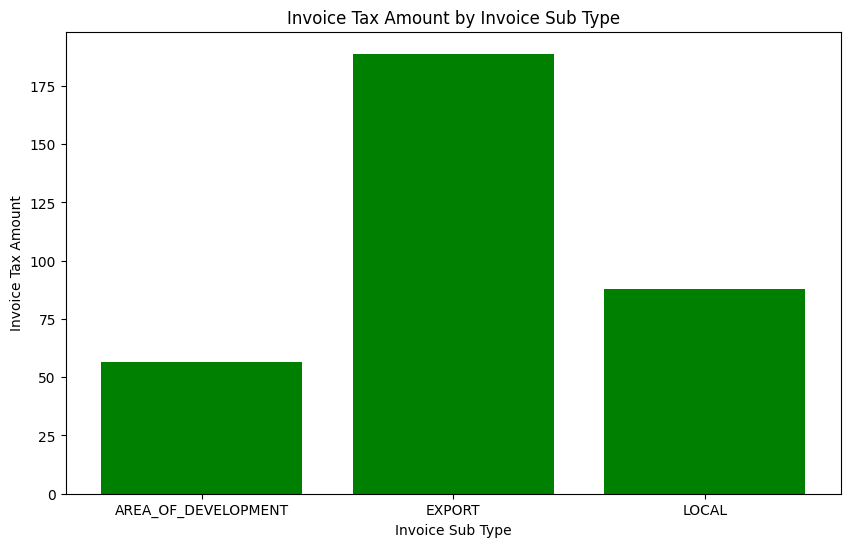

In [8]:
aggregated = df.groupby('invoice_sub_type')['invoice_tax_amount'].mean()

plt.figure(figsize=(10,6))
plt.bar(aggregated.index, aggregated.values, color='green')
plt.title("Invoice Tax Amount by Invoice Sub Type")
plt.xlabel("Invoice Sub Type")
plt.ylabel("Invoice Tax Amount")
plt.show()

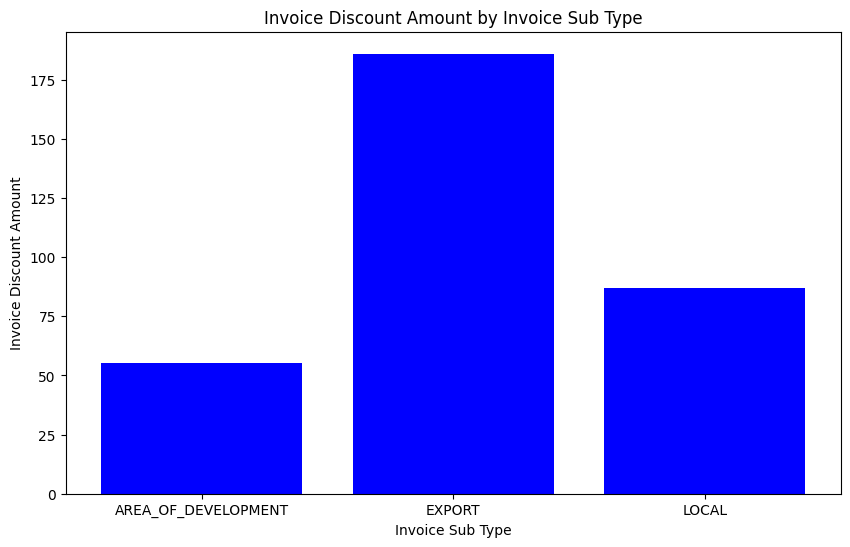

In [9]:
aggregated = df.groupby('invoice_sub_type')['invoice_discount_amount'].mean()
plt.figure(figsize=(10,6))
plt.bar(aggregated.index, aggregated.values, color='blue')
plt.title("Invoice Discount Amount by Invoice Sub Type")
plt.xlabel("Invoice Sub Type")
plt.ylabel("Invoice Discount Amount")
plt.show()

Measurs of central tendency

In [25]:
print(f"days overdue mean is : {df['days_overdue'].mean()}")
print(f"days overdue median is : {df['days_overdue'].median()}")
print(f"days overdue mode is : {df['days_overdue'].mode()[0]}")
# seeing that the mean is greater than the median indicates that the data is left skewed
# this means that there are some invoices with very high days overdue that are affecting the mean
# which indicates that we have outliers in the days overdue column

days overdue mean is : 6.792668830595218
days overdue median is : 3.0
days overdue mode is : 0


In [26]:
# discount amount mean, mode and median 
print(f"invoice discount amount mean is : {df['invoice_discount_amount'].mean()}")
print(f"invoice discount amount median is : {df['invoice_discount_amount'].median()}")
print(f"invoice discount amount mode is : {df['invoice_discount_amount'].mode()[0]}")

invoice discount amount mean is : 109.60033829082224
invoice discount amount median is : 0.0
invoice discount amount mode is : 0.0


In [27]:
#exploring expected payment amount column
print(f"expected payment amount mean is : {df['expected_payment_amount'].mean()}")
print(f"expected payment amount median is : {df['expected_payment_amount'].median()}")
print(f"expected payment amount mode is : {df['expected_payment_amount'].mode()[0]}")

expected payment amount mean is : 1620.3164399678983
expected payment amount median is : 1178.54
expected payment amount mode is : 378.38


Measures of position

In [14]:
from scipy import stats

numeric_cols = ['days_overdue', 'expected_payment_amount', 'invoice_tax_amount', 'invoice_discount_amount']

for i in numeric_cols:
    z_scores = stats.zscore(df[i])
    z_scores_count = np.sum(np.abs(z_scores) > 3)
    print(f"Number of outliers in {i} (|z| > 3): {z_scores_count}")
    
    z_scores_range = (z_scores.min(), z_scores.max())
    print(f"Z-scores range for {i}: \n {z_scores_range}\n")
    

# calculating the z-score allowed me to identify the number of outliers in all of the numerical columns


Number of outliers in days_overdue (|z| > 3): 2344
Z-scores range for days_overdue: 
 (np.float64(-0.4342660625741475), np.float64(32.17084062469064))

Number of outliers in expected_payment_amount (|z| > 3): 2408
Z-scores range for expected_payment_amount: 
 (np.float64(-0.5453748753740327), np.float64(36.73004501770307))

Number of outliers in invoice_tax_amount (|z| > 3): 1601
Z-scores range for invoice_tax_amount: 
 (np.float64(-0.40293366926188845), np.float64(57.63189899540853))

Number of outliers in invoice_discount_amount (|z| > 3): 4015
Z-scores range for invoice_discount_amount: 
 (np.float64(-0.22967873613818707), np.float64(97.61284651713517))



C:\Users\MAA\AppData\Local\Temp\ipykernel_21616\3107828475.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(df['days_overdue'], labels=['days_overdue'])


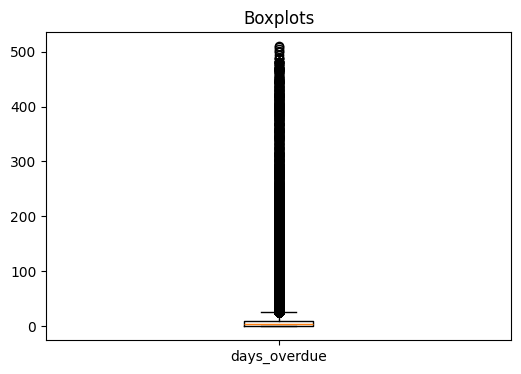

In [15]:
# df is your DataFrame
plt.figure(figsize=(6,4))
plt.boxplot(df['days_overdue'], labels=['days_overdue'])
plt.title('Boxplots')
plt.show()

In [16]:
#IQR of days overdue 
Q1 = df['days_overdue'].quantile(0.25)
Q3 = df['days_overdue'].quantile(0.75)
IQR = Q3 - Q1
print(f"the interquartile range (IQR) of days overdue is : {IQR}")

the interquartile range (IQR) of days overdue is : 10.0


Measures of dispersion

In [17]:
#calculate IQR for days overdue 
Q1 = df['days_overdue'].quantile(0.25)
Q3 = df['days_overdue'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers = df[(df['days_overdue'] < lower_bound) | (df['days_overdue'] > upper_bound)]
print(f"Number of outliers in days_overdue using IQR method: {outliers.shape[0]}")

# The IQR method also helped me to identify the number of outliers in the days overdue column

Number of outliers in days_overdue using IQR method: 16681


In [18]:
#range of days overdue
days_overdue_range = df['days_overdue'].max() - df['days_overdue'].min()
print(f"Range of days overdue: {days_overdue_range}")
                                                   

Range of days overdue: 510


In [19]:
print(f"the Range of invoice_discount_amount is : {df['invoice_discount_amount'].max() - df['invoice_discount_amount'].min()}")

print(f"the range of expected_payment_amount is : {df['expected_payment_amount'].max() - df['expected_payment_amount'].min()}")

the Range of invoice_discount_amount is : 46689.45
the range of expected_payment_amount is : 109152.6


In [20]:
#IQR of days overdue 
Q1 = df['days_overdue'].quantile(0.25)
Q3 = df['days_overdue'].quantile(0.75)
IQR = Q3 - Q1
print(f"the interquartile range (IQR) of days overdue is : {IQR}")

#coefficient of variation (CV) for days overdue
cv_days_overdue = (df['days_overdue'].std() / df['days_overdue'].mean()) * 100
print(f"the coefficient of variation (CV) for days overdue is : {cv_days_overdue}%")


the interquartile range (IQR) of days overdue is : 10.0
the coefficient of variation (CV) for days overdue is : 230.27379432384706%


Visualizations

<Figure size 1200x800 with 0 Axes>

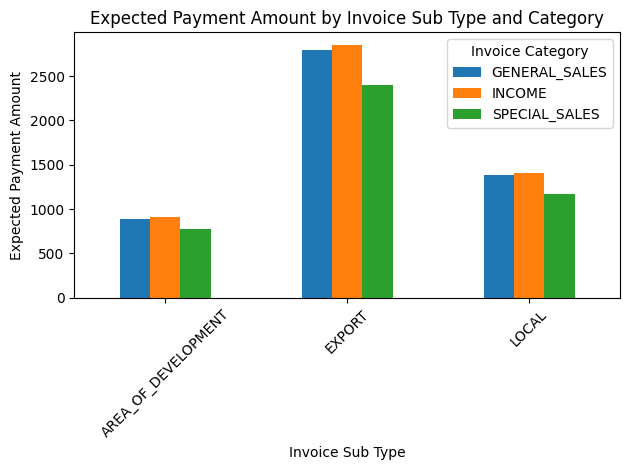

In [21]:
multi_bar = df.groupby(['invoice_sub_type', 'invoice_category'])['expected_payment_amount'].mean().unstack()
plt.figure(figsize=(12,8))
multi_bar.plot(kind='bar')
plt.title("Expected Payment Amount by Invoice Sub Type and Category")
plt.xlabel("Invoice Sub Type")
plt.ylabel("Expected Payment Amount")
plt.xticks(rotation=45)
plt.legend(title='Invoice Category')
plt.tight_layout()
plt.show()
# this grouped bar chart allows me to compare the expected payment amounts across different invoice sub types and categories
# it helps to identify which combinations of sub types and categories have higher or lower expected payments

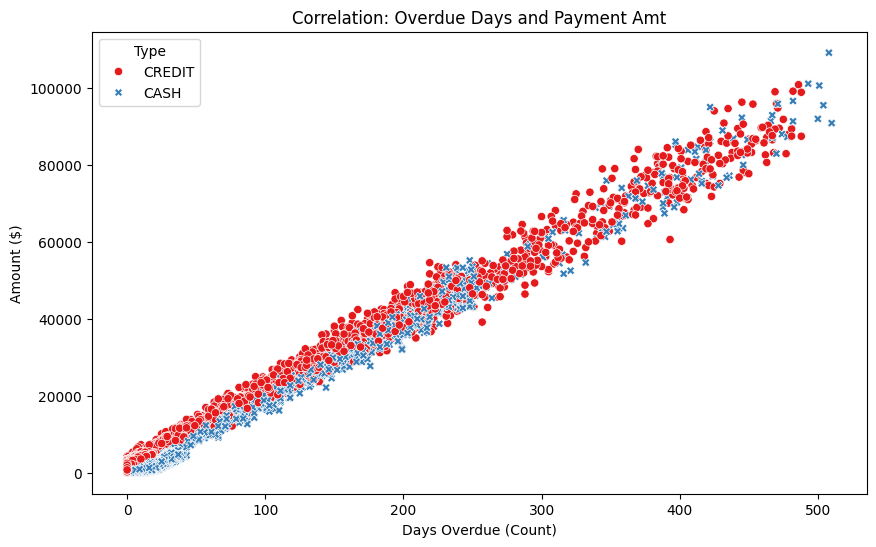

In [22]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x = "days_overdue", y = "expected_payment_amount", hue="collection_type", style="collection_type", markers=["o", "X"], palette="Set1")

plt.title('Correlation: Overdue Days and Payment Amt') 
plt.xlabel('Days Overdue (Count)')
plt.ylabel('Amount ($)')
plt.legend(title='Type', loc='upper left') 
plt.show()

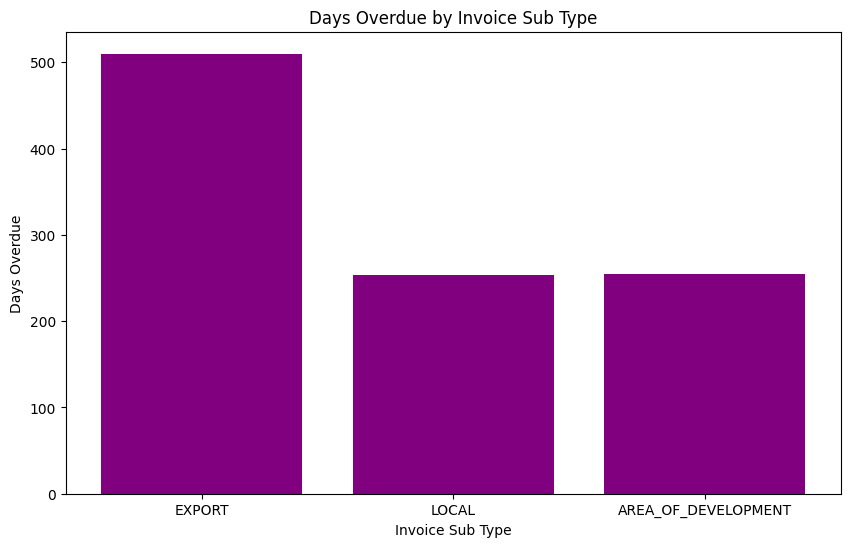

In [30]:
plt.figure(figsize=(10,6))
plt.bar(df['invoice_sub_type'] , df['days_overdue'] , color = 'purple')
plt.title("Days Overdue by Invoice Sub Type")
plt.xlabel("Invoice Sub Type")
plt.ylabel("Days Overdue")
plt.show()